# [실습] 분류 — 확률을 예측하고 선을 긋기

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

# Chapter 3 실습. 1,000통으로 가입을 가장 많이 얻으려면?

**필수 머신러닝 · Chapter 3**

| Part | 주제 |
| --- | --- |
| Part 1 | 데이터와 친해지기 |
| Part 2 | 현행 방법 만들기: 사람이 쓰는 선정 규칙 |
| Part 3 | 모델과 임계값 |
| Part 4 | 통화 예산 곡선과 결정 |

## 분석 의뢰서

> **의뢰 부서**: 은행 마케팅팀
> **목적**: 정기예금 상품 가입을 권유하는 전화 캠페인을 하려 한다. 가입할 가능성이 높은 고객에게 먼저 전화하고 싶다.
> **제약**: 콜센터가 이번 캠페인에 걸 수 있는 전화는 약 1,000통이다. 고객은 9,000명이 넘는다.
> **질문**: 누구에게 전화해야 가입을 가장 많이 얻을 수 있을까?

## 이 실습의 질문

> **1,000통으로 가입을 가장 많이 얻으려면 누구에게 전화해야 하는가? 그리고 전화를 2,000통으로 늘리면 가입이 얼마나 늘어나는가?**

Chapter 1, 2와 같은 순서로 진행합니다. 여러분이 먼저 마케팅팀 담당자처럼 **사람이 쓰는 선정 규칙**을 만들고, 그 규칙과 모델을 **같은 평가용 데이터**에서 비교합니다. 마지막에는 마케팅팀에 보낼 보고 메모를 씁니다.

## 이 노트북을 쓰는 법

| 표시 | 뜻 |
| --- | --- |
| **[직접 작성]** | 빈 코드 셀을 직접 채웁니다. 강의 교안의 코드를 보지 않고 먼저 써 보세요 |
| **[판단]** | 코드가 아니라 생각을 적는 칸입니다. 셀을 더블클릭해 `나의 답:` 뒤에 적으세요 |
| **[제공]** | 미리 채워 둔 코드입니다. 읽고 실행하세요 |
| **힌트** | 막혔을 때만 펼치세요 |

## 준비

UCI Bank Marketing 데이터의 `bank-full.csv`(통화 45,211건)를 이 노트북과 같은 폴더에 두세요. 이 파일은 열을 쉼표가 아니라 세미콜론(`;`)으로 구분합니다.

In [1]:
# [제공] 이 실습에서 쓰는 라이브러리
import platform
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score)

# 그래프의 한글 글꼴 (환경에 맞는 글꼴이 없으면 글자가 깨질 수 있습니다)
if platform.system() == "Windows":
    plt.rcParams["font.family"] = "Malgun Gothic"
elif platform.system() == "Darwin":
    plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

In [2]:
# [환경] 그래프 한글 글꼴 등록 (같은 폴더의 fonts/NanumGothic-Regular.ttf)
import os
import matplotlib.font_manager as fm
for _p in ["fonts/NanumGothic-Regular.ttf", "../fonts/NanumGothic-Regular.ttf", "NanumGothic-Regular.ttf"]:
    if os.path.exists(_p):
        fm.fontManager.addfont(_p)
        plt.rcParams["font.family"] = fm.FontProperties(fname=_p).get_name()
        break
plt.rcParams["axes.unicode_minus"] = False

---
# Part 1. 데이터와 친해지기

## 1-1. 데이터 불러오기

**[직접 작성]** `bank-full.csv`를 불러와 `df`에 저장하고, 행과 열의 수와 처음 5행을 확인하세요.

<details><summary>힌트</summary>

구분자가 세미콜론이므로 `pd.read_csv("bank-full.csv", sep=";")`처럼 `sep`을 알려 줘야 합니다.
</details>

In [3]:
df = pd.read_csv("bank-full.csv", sep=";")
print("행·열:", df.shape)
df.head()

행·열: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


원본 데이터에는 통화 시간(`duration`)이라는 열이 있습니다. 이 실습에서는 **쓰지 않습니다.** 이유는 Chapter 4에서 다룹니다. **[제공]** 셀을 실행해 이 열을 제외하세요.

In [4]:
# [제공] 통화 시간 열 제외
df = df.drop(columns=["duration"])
print(df.columns.tolist())

['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'campaign', 'pdays', 'previous', 'poutcome', 'y']


## 1-2. 맞히려는 값 만들기

결과 열 `y`는 "yes"/"no" 글자입니다. 모델이 다룰 수 있도록 0과 1로 바꿉니다.

**[직접 작성]** 가입(`yes`)이면 1, 아니면 0인 열 `target`을 `df`에 만들고, `target`의 값별 개수와 비율을 확인하세요.

<details><summary>힌트</summary>

`df["target"] = (df["y"] == "yes").astype(int)`, 비율은 `df["target"].value_counts(normalize=True)`.
</details>

In [5]:
df["target"] = (df["y"] == "yes").astype(int)
print(df["target"].value_counts())
print()
print((df["target"].value_counts(normalize=True) * 100).round(2))

target
0    39922
1     5289
Name: count, dtype: int64

target
0    88.3
1    11.7
Name: proportion, dtype: float64


> **[판단]** "전부 미가입"이라고 답하는 방법의 정확도는 얼마인가요? 이 방법은 콜센터에 어떤 가치가 있을까요?
>
> 나의 답:

전부 미가입이라고 답하면 정확도는 **88.3%**(평가용 9,043명 중 7,985명)입니다. 그런데 이 방법이 콜센터에 주는 가치는 없습니다. 가입 고객 1,058명을 한 명도 찾지 못하고(재현율 0%), 전화를 한 통도 걸지 않으니 가입도 0건이기 때문입니다. 정확도가 높다는 것은 이 데이터에서 "아무것도 하지 않는다"는 뜻과 같습니다. 그래서 이 문제에서는 정확도 대신 '상위 N명 중 가입 수'나 재현율을 봐야 합니다.


## 1-3. 데이터의 결함 찾기

**[직접 작성]** 아래 두 가지를 확인하세요.

1. `pdays`(이전 캠페인 이후 경과일)가 `-1`인 행의 비율
2. 글자로 된 열마다 `"unknown"`이라는 값이 몇 개 있는지

<details><summary>힌트</summary>

비율은 `(df["pdays"] == -1).mean()`. `"unknown"`은 `df.select_dtypes("object")`로 글자 열만 고른 뒤 `(열 == "unknown").sum()`을 세면 됩니다. 글자 열이 아닌 `target` 같은 열은 건너뜁니다.
</details>

In [6]:
print("pdays == -1 비율:", round((df["pdays"] == -1).mean(), 4))

text_cols = [c for c in df.columns if df[c].dtype == object or pd.api.types.is_string_dtype(df[c])]
unknown = {c: int((df[c] == "unknown").sum()) for c in text_cols if (df[c] == "unknown").any()}
print("열마다 unknown 개수:")
for c, n in unknown.items():
    print(f"  {c}: {n}건 ({n / len(df) * 100:.2f}%)")

pdays == -1 비율: 0.8174
열마다 unknown 개수:
  job: 288건 (0.64%)
  education: 1857건 (4.11%)
  contact: 13020건 (28.80%)
  poutcome: 36959건 (81.75%)


> **[판단]** `pdays`의 −1은 어떤 뜻일까요? 이 열을 숫자 그대로 모델에 넣으면 어떤 문제가 생길까요?
>
> 나의 답:

`pdays`가 -1인 행은 **81.7%**입니다. -1은 "이전 캠페인에서 연락한 적이 없다"는 뜻으로, 실제 값(경과 일수)이 아니라 **결측 표시**입니다. 이대로 숫자로 넣으면 모델은 -1을 "아주 오래전에 연락했다" 또는 "가장 가까운 시점"으로 거리 계산에 쓰게 되어 의미가 뒤집힙니다. 그래서 (1) 연락 이력 여부를 0/1로 만들고 실제 일수는 연락한 적 있는 고객에만 두거나, (2) -1을 별도 범주로 두는 방식이 안전합니다.


> **[판단]** `unknown`이 많은 열(`contact`, `poutcome`)은 어떻게 다루겠습니까? (예: 그대로 하나의 값으로 둔다 / 뺀다) 선택과 이유를 적으세요.
>
> 나의 답:

`contact`의 unknown은 **28.8%**, `poutcome`의 unknown은 **81.7%**입니다. 나는 둘 다 **빼지 않고 하나의 값으로 그대로** 둡니다. 이유는 unknown이 무작위 결측이 아니라 정보이기 때문입니다. `contact`가 unknown인 고객의 가입률은 4.1%로 cellular(14.8%)의 1/3 수준이고, `poutcome`이 unknown(이전 캠페인 없음)인 고객의 가입률은 9.2%로 success(64.6%)와 뚜렷이 다릅니다. 원핫 인코딩으로 한 범주로 두면 모델이 이 차이를 학습할 수 있습니다. 다만 `poutcome`은 81.7%가 unknown이라 변별력이 크지 않고, 보고서에는 "대부분이 이전 캠페인 이력 없음"이라는 사실을 함께 적어야 합니다.


## 1-4. 평가용 데이터 먼저 떼어 두기

Chapter 1, 2와 같은 원칙입니다. 이후의 탐색과 규칙 만들기는 **학습용 데이터만** 보고 하고, 평가용 데이터는 마지막 채점에만 씁니다.

**[직접 작성]** `df`를 학습용 80%, 평가용 20%로 나눠 `train_df`, `test_df`에 저장하세요. `random_state=42`, 그리고 가입 비율이 두 쪽에 같게 `target`으로 `stratify`합니다.

<details><summary>힌트</summary>

`train_df, test_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df["target"])`
</details>

In [7]:
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df["target"])
print("학습용", len(train_df), "| 평가용", len(test_df))
print("학습용 가입률", round(train_df["target"].mean(), 4), "| 평가용 가입률", round(test_df["target"].mean(), 4))

학습용 36168 | 평가용 9043
학습용 가입률 0.117 | 평가용 가입률 0.117


> **[판단]** 왜 가입 비율이 두 쪽에 같도록(`stratify`) 나눌까요? 가입이 11.7%뿐인 데이터를 그냥 무작위로 나누면 어떤 일이 생길 수 있나요?
>
> 나의 답:

가입률이 11.7%뿐인 데이터를 그냥 무작위로 나누면, 평가용 9,000명 안에 가입 고객이 800명 정도일 때도 있고 1,300명일 때도 있습니다. 가입 고객 수가 흔들리면 정확도·재현율·상위 1,000명 가입 수가 함께 흔들려서, 모델끼리 점수를 비교할 수 없게 됩니다. `stratify`를 쓰면 학습용 36,168명과 평가용 9,043명 모두 가입률이 **11.7%**로 같아져, 이후 모든 비교가 "같은 조건"에서 이뤄집니다.


### 체크포인트

여기까지 막혀서 다음으로 넘어가지 못했다면 **아래 셀만 실행**하세요. 끝낸 사람은 실행하지 않아도 됩니다.

In [8]:
# [제공] 체크포인트: 1-4까지 끝낸 사람은 실행하지 않아도 됩니다
df = pd.read_csv("bank-full.csv", sep=";").drop(columns=["duration"])
df["target"] = (df["y"] == "yes").astype(int)
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df["target"])
print(len(train_df), len(test_df))

36168 9043


### 실습 도구 (실행만 하세요)

| 도구 | 하는 일 |
| --- | --- |
| `rate_by(열 이름)` | 학습용 데이터에서 그 열의 값별 가입률과 통화 수를 계산한다 (숫자 열은 `bins`로 구간을 나눈다) |
| `evaluate_selection(이름, 선정 여부)` | 평가용 데이터에서 선정한 고객 수와 그중 실제 가입 수를 보여 준다 |
| `make_data(피처 목록)` | 피처 목록으로 학습용·평가용 `X`, `y`를 만든다 |
| `record(이름, 피처, 확률)` | 모델의 점수(AUC, 상위 $N$명 가입 수)를 기록표에 남긴다 |
| `run_logistic(이름, 피처, ...)` | 로지스틱 회귀를 학습하고 점수를 기록한다 |

In [9]:
# [제공] 실습 도구
y_test = test_df["target"]
base_rate = y_test.mean()
experiment_log = []
probs = {}          # 실험 이름 → 평가용 데이터의 가입 확률

def rate_by(col, bins=None):
    """학습용 데이터에서 col의 값별 가입률과 통화 수를 계산합니다. 숫자 열은 bins로 구간을 나눕니다."""
    key = pd.cut(train_df[col], bins) if bins is not None else train_df[col]
    out = train_df.groupby(key, observed=True)["target"].agg(["mean", "size"])
    out.columns = ["가입률", "통화 수"]
    return out.round(3)

def evaluate_selection(name, mask):
    """평가용 데이터에서 선정한 고객(True)을 채점합니다. (선정 수, 그중 가입 수)를 돌려줍니다."""
    mask = pd.Series(np.asarray(mask), index=test_df.index)
    n_sel = int(mask.sum()); hits = int(y_test[mask].sum()); total = int(y_test.sum())
    print(f"[{name}] 선정 {n_sel:,}명 | 그중 실제 가입 {hits}명 ({hits / n_sel * 100:.1f}%) | "
          f"무작위로 {n_sel:,}명을 골랐다면 약 {n_sel * base_rate:.0f}명 | 전체 가입 고객 {total}명 중 {hits / total * 100:.1f}%를 찾음")
    return n_sel, hits

def make_data(features):
    X = pd.get_dummies(df[features]).astype(float)
    return X.loc[train_df.index], X.loc[test_df.index], train_df["target"], test_df["target"]

def summarize(prob):
    prob = np.asarray(prob)
    ys = y_test.values[np.argsort(-prob, kind="stable")]
    return {"ROC AUC": roc_auc_score(y_test, prob), "PR AUC": average_precision_score(y_test, prob),
            "상위 1,000명 가입": int(ys[:1000].sum()), "상위 2,000명 가입": int(ys[:2000].sum())}

def record(name, features, prob):
    s = summarize(prob)
    experiment_log.append({"실험": name, "피처 수": len(features),
                           "ROC AUC": round(s["ROC AUC"], 3), "PR AUC": round(s["PR AUC"], 3),
                           "상위 1,000명 가입": s["상위 1,000명 가입"], "상위 2,000명 가입": s["상위 2,000명 가입"]})
    probs[name] = np.asarray(prob)
    print(f"기록: [{name}] ROC AUC {s['ROC AUC']:.3f} | PR AUC {s['PR AUC']:.3f} | 상위 1,000명 중 가입 {s['상위 1,000명 가입']}명")

def run_logistic(name, features, **model_kwargs):
    """피처 목록으로 로지스틱 회귀를 학습하고(스케일링 포함) 점수를 기록합니다."""
    X_tr, X_te, y_tr, _ = make_data(features)
    scaler = StandardScaler().fit(X_tr)
    model = LogisticRegression(max_iter=3000, **model_kwargs).fit(scaler.transform(X_tr), y_tr)
    prob = model.predict_proba(scaler.transform(X_te))[:, 1]
    record(name, features, prob)

## 1-5. 가입률이 높은 집단 찾기

학습용 데이터에서 "어떤 고객이 많이 가입하는가"를 찾아봅니다. 이 관찰이 Part 2에서 규칙의 재료가 됩니다. 전체 가입률은 11.7%입니다.

**[직접 작성]** `rate_by`로 다음을 확인하세요. 결과의 **통화 수**도 함께 봅니다.

- `poutcome`(이전 캠페인 결과), `contact`(연락 수단), `housing`(주택 대출), `month`(통화 월) 중 **세 개 이상**
- 나이는 구간으로: `rate_by("age", bins=[17, 25, 35, 45, 55, 65, 100])`

<details><summary>힌트</summary>

한 줄에 하나씩 `print(rate_by("열 이름"))`을 쓰세요. 결과를 가입률 순으로 보려면 `.sort_values("가입률", ascending=False)`를 붙입니다.
</details>

In [10]:
for col in ["poutcome", "contact", "housing", "month"]:
    print(f"[{col}]")
    print(rate_by(col).sort_values("가입률", ascending=False))
    print()
print("[age] 10년 구간")
print(rate_by("age", bins=[17, 25, 35, 45, 55, 65, 100]).sort_values("가입률", ascending=False))

[poutcome]
            가입률   통화 수
poutcome              
success   0.646   1205
other     0.165   1485
failure   0.123   3889
unknown   0.092  29589

[contact]
             가입률   통화 수
contact                
cellular   0.148  23465
telephone  0.139   2317
unknown    0.041  10386

[housing]
           가입률   통화 수
housing              
no       0.167  15986
yes      0.077  20182

[month]
         가입률   통화 수
month              
mar    0.509    391
dec    0.472    178
sep    0.452    451
oct    0.438    592
apr    0.195   2394
feb    0.168   2078
aug    0.109   4986
jun    0.104   4237
jan    0.102   1119
nov    0.101   3143
jul    0.093   5537
may    0.067  11062

[age] 10년 구간
             가입률   통화 수
age                    
(65, 100]  0.427    609
(17, 25]   0.244   1079
(55, 65]   0.141   3282
(25, 35]   0.119  12511
(35, 45]   0.095  11098
(45, 55]   0.092   7589


> **[판단]** 가입률이 전체 평균(11.7%)보다 눈에 띄게 높은 집단을 두 개 이상 적어 보세요. (예: "○○인 고객은 가입률 △△%")
>
> 나의 답:

가입률이 눈에 띄게 높은 집단은 다음과 같습니다.
- 이전 캠페인 성공(`poutcome`=success): **64.6%** (1,205건)
- 65세 초과: **42.7%** (609건)
- 17~25세: **24.4%** (1,079건)
- 주택 대출 없음(`housing`=no): **16.7%** (15,986건)
- 3월(50.9%)·12월(47.2%)·9월(45.2%)·10월(43.8%) 통화

전체 평균의 1.4~5.5배로, 모두 "전체 평균 11.7%"와 뚜렷이 다릅니다.


> **[판단]** 3월의 가입률은 매우 높지만 통화 수는 매우 적습니다. 통화 수가 적은 집단의 가입률을 얼마나 믿을 수 있을까요? 규칙의 근거로 쓸 때 어떤 점을 조심해야 하나요?
>
> 나의 답:

3월의 가입률은 50.9%로 전체(11.7%)의 네 배가 넘지만 통화 수는 **391건**뿐입니다. 391건에서 1~2건만 결과가 달라져도 가입률은 1%p 이상 움직이므로, 이 숫자는 "3월이 좋다"기보다 "3월에 걸었던 소수 고객이 우연히 좋았다"일 수 있습니다. 규칙의 근거로 쓸 때는 (1) 통화 수가 충분한지(수백 건 이상), (2) 다른 해·다른 기간에도 반복되는지, (3) 그 달에 특별한 캠페인이 있었는지를 함께 봐야 합니다. 그래서 나는 3월을 규칙에 넣지 않았습니다.


---
# Part 2. 현행 방법 만들기: 사람이 쓰는 선정 규칙

여러분이 마케팅팀 담당자라고 생각해 보세요. 머신러닝 없이, 전화할 고객을 고르는 **규칙 하나**를 만들어 봅시다. 강의 Part 2에서 본 것처럼, 규칙은 "이 조건에 맞는 고객"을 고를 뿐 순위를 매기지는 못합니다. 그 한계가 실제로 무엇인지 직접 확인합니다.

## 규칙을 만들 때의 약속

- 조건은 **두세 개를 넘기지 않습니다.**
- 근거는 **1-5에서 본 집계**입니다. 평가용 데이터를 보고 규칙을 고치지 않습니다.
- 규칙은 "이 조건에 맞는 고객에게 전화한다"입니다.

## 2-1. 나의 규칙 만들기

> **[판단]** 나의 규칙(말로): 만약 ______ 이면 전화한다.
>
> 이 조건을 고른 근거(1-5의 어떤 집계인가):
>
> 나의 답:

**나의 규칙:** 이전 캠페인에서 성공한 고객이거나, 60세를 초과한 고객이면 전화한다.
**근거:** 1-5에서 `poutcome`=success의 가입률이 64.6%(1,205건), 65세 초과가 42.7%(609건)로 전체 평균(11.7%)의 3.6~5.5배였습니다. 통화 수가 1,000건 안팎이라 3월(391건)처럼 우연에 기대기 어렵다고 판단했습니다. 조건은 두 개, 강한 조건을 "또는"으로 묶었습니다.


**[직접 작성]** 규칙을 코드로 옮겨 평가용 고객 중 선정할 고객을 `True`/`False`로 표시한 `selected`를 만드세요. 그다음 `evaluate_selection`으로 채점하고, 결과를 `rule_n, rule_hits`에 저장하세요.

<details><summary>힌트</summary>

조건은 `&`(그리고), `|`(또는)로 묶고, 조건마다 괄호를 칩니다.

```python
selected = (test_df["contact"] == "cellular") & (test_df["housing"] == "no")
rule_n, rule_hits = evaluate_selection("내 규칙", selected)
```

이 예시는 형식만 보여 주는 것입니다. 여러분의 규칙을 쓰세요.
</details>

In [11]:
selected = (test_df["poutcome"] == "success") | (test_df["age"] > 60)
rule_n, rule_hits = evaluate_selection("나의 규칙: 이전 캠페인 성공 또는 60세 초과", selected)

[나의 규칙: 이전 캠페인 성공 또는 60세 초과] 선정 484명 | 그중 실제 가입 265명 (54.8%) | 무작위로 484명을 골랐다면 약 57명 | 전체 가입 고객 1058명 중 25.0%를 찾음


> **[판단]** 내 규칙은 무작위로 같은 수의 고객을 골랐을 때보다 가입을 몇 배 더 얻었나요? 선정한 고객 수는 콜센터의 1,000통과 비교해 어떤가요?
>
> 나의 답:

내 규칙은 평가용에서 **484명**을 골라 **265명**(54.8%)의 가입을 얻었습니다. 무작위로 484명을 골랐다면 약 57명이었으니 **4.6배**입니다. 다만 484명은 콜센터의 1,000통에 비해 절반도 안 됩니다. 남는 516통으로는 아무에게나 거는 대신 다음 조건(예: 25세 이하, 주택 대출 없음)을 완화해 채워야 합니다.


## 2-2. 규칙을 넓혀 1,000통을 채워 보기

콜센터는 약 1,000통을 걸 수 있습니다. 내 규칙이 고른 고객이 1,000명보다 훨씬 적다면 남는 전화는 어떻게 쓸까요? 조건을 **하나 완화**해 선정 고객을 약 1,000~2,000명으로 늘려 보세요.

**[직접 작성]** 규칙을 느슨하게 바꾼 `selected_wide`를 만들어 `evaluate_selection`으로 채점하고, 결과를 `wide_n, wide_hits`에 저장하세요. (이미 1,000명 이상을 고르는 규칙이라면 조건을 하나 추가해 줄여 보세요.)

<details><summary>힌트</summary>

예를 들어 `|`(또는)로 조건을 하나 더하면 선정이 늘고, `&`(그리고)로 조건을 하나 더하면 줄어듭니다. 나이 기준을 넓히거나, 월을 몇 개 더 포함하는 식으로 바꿔 보세요.
</details>

In [12]:
selected_wide = selected | ((test_df["contact"] == "cellular") & (test_df["housing"] == "no") & (test_df["campaign"] <= 2))
wide_n, wide_hits = evaluate_selection("나의 규칙(넓힘): + 휴대전화·주택대출 없음·통화 2회 이하", selected_wide)

[나의 규칙(넓힘): + 휴대전화·주택대출 없음·통화 2회 이하] 선정 2,169명 | 그중 실제 가입 566명 (26.1%) | 무작위로 2,169명을 골랐다면 약 254명 | 전체 가입 고객 1058명 중 53.5%를 찾음


> **[판단]** 규칙을 넓히자 선정 고객 수와 가입률이 어떻게 변했나요? "가입 가능성이 높은 순서대로 1,000명"을 규칙만으로 고를 수 있을까요? 못 한다면 이유는 무엇인가요?
>
> 나의 답:

규칙을 넓히자 선정 고객은 484명 → **2,169명**, 가입은 265명 → **566명**으로 늘었지만 가입률은 54.8% → **26.1%**로 떨어졌습니다(무작위 대비 4.6배 → 2.2배). 규칙만으로 "가능성이 높은 순서대로 1,000명"을 고를 수는 없습니다. 규칙은 조건에 맞는지 아닌지만 판단할 뿐, 조건을 통과한 2,169명 **안에서 누가 더 유망한지 순서를 매기지 못하기** 때문입니다. 조건을 두세 개 조합하면 "어느 조건이 더 강한지"를 정할 근거도 사라집니다. 순위를 매기려면 확률이 필요하고, 그것이 모델입니다.


---
# Part 3. 모델과 임계값

이제 모델이 **확률로 순위를 매기게** 해 봅니다. 강의 Part 1의 코드를 보지 말고 먼저 직접 써 보세요.

## 3-1. 첫 모델: 로지스틱 회귀

**[제공]** 강의에서 쓴 기본 피처 목록입니다.

In [13]:
# [제공] 기본 피처 목록 (통화 시간은 제외)
base_features = ["age", "balance", "campaign", "previous", "poutcome", "housing",
                 "loan", "contact", "month", "job", "marital", "education"]

**[직접 작성]** 아래 순서로 작성하세요.

1. `make_data(base_features)`로 `X_train, X_test, y_train, y_test`를 만든다
2. `StandardScaler`를 학습용 데이터로 학습(`fit`)하고, 학습용과 평가용에 적용(`transform`)한다
3. `LogisticRegression(max_iter=2000)`을 학습한다
4. 평가용 고객의 **가입 확률**을 `prob`에 저장한다 (`predict_proba`의 두 번째 열)

<details><summary>힌트</summary>

강의 1-6과 같은 순서입니다. 확률은 `model.predict_proba(X_test_scaled)[:, 1]`입니다.
</details>

In [14]:
X_train, X_test, y_train, y_test = make_data(base_features)
scaler = StandardScaler().fit(X_train)
model = LogisticRegression(max_iter=2000).fit(scaler.transform(X_train), y_train)
prob = model.predict_proba(scaler.transform(X_test))[:, 1]
print("피처 수:", X_train.shape[1], "| 평가용 ROC AUC:", round(roc_auc_score(y_test, prob), 3))

피처 수: 46 | 평가용 ROC AUC: 0.773


## 3-2. 정확도는 속인다

**[직접 작성]** 임계값 0.5로 가입 여부를 예측했을 때(`pred = (prob >= 0.5).astype(int)`) 아래를 계산해 출력하세요.

- 정확도, 그리고 "전부 미가입" 베이스라인의 정확도
- 혼동행렬
- 정밀도와 재현율

<details><summary>힌트</summary>

정확도는 `(pred == y_test).mean()`, 베이스라인은 `(y_test == 0).mean()`. 나머지는 `confusion_matrix(y_test, pred)`, `precision_score(y_test, pred)`, `recall_score(y_test, pred)`입니다.
</details>

In [15]:
pred = (prob >= 0.5).astype(int)
acc = (pred == y_test).mean()
base_acc = (y_test == 0).mean()
cm = confusion_matrix(y_test, pred)
print("모델 정확도:", round(acc, 3), "| 전부 미가입 정확도:", round(base_acc, 3), "| 차이:", round(acc - base_acc, 3))
print("혼동행렬 [[TN, FP], [FN, TP]]:")
print(cm)
print("정밀도:", round(precision_score(y_test, pred), 3), "| 재현율:", round(recall_score(y_test, pred), 3))

모델 정확도: 0.893 | 전부 미가입 정확도: 0.883 | 차이: 0.01
혼동행렬 [[TN, FP], [FN, TP]]:
[[7886   99]
 [ 866  192]]
정밀도: 0.66 | 재현율: 0.181


> **[판단]** 정확도는 베이스라인보다 얼마나 높은가요? 그런데 가입할 고객 중 모델이 찾아낸 비율(재현율)은 얼마인가요? 두 숫자가 이렇게 다른 이유를 설명해 보세요.
>
> 나의 답:

모델 정확도는 **0.893**, 전부 미가입 베이스라인은 **0.883**으로 차이가 **+1.0%p**에 불과합니다. 그런데 재현율은 **18.1%**로, 실제 가입 고객 1,058명 중 **192명**만 찾고 **866명**을 놓쳤습니다(정밀도 0.660). 두 숫자가 이렇게 다른 이유는 데이터가 88.3% 미가입이기 때문입니다. 모두 0으로 찍어도 정확도가 88%이므로, 정확도는 "가입 고객을 잘 찾는가"를 전혀 말해 주지 않습니다. 임계값 0.5는 확률이 낮게 깔린 이 데이터에서 지나치게 보수적이어서, 소수의 확실한 고객만 가입으로 예측했습니다.


## 3-3. 임계값을 움직이면

**[직접 작성]** 임계값을 `[0.5, 0.4, 0.3, 0.2, 0.15, 0.1, 0.05]`로 바꿔 가며, 임계값마다 다음을 계산해 하나의 표(`DataFrame`)로 출력하세요.

- 가입으로 예측한 고객 수
- TP(찾은 가입), FP(헛걸음), FN(놓친 가입)
- 정밀도, 재현율

<details><summary>힌트</summary>

```python
rows = []
for t in [0.5, 0.4, ...]:
    pred = (prob >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rows.append({"임계값": t, "예측 가입 수": pred.sum(), "TP": tp, "FP": fp, "FN": fn,
                 "정밀도": round(tp / (tp + fp), 3), "재현율": round(tp / (tp + fn), 3)})
pd.DataFrame(rows)
```
</details>

In [16]:
rows = []
for t in [0.5, 0.4, 0.3, 0.2, 0.15, 0.1, 0.05]:
    p = (prob >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, p).ravel()
    rows.append({"임계값": t, "예측 가입 수": int(p.sum()), "TP": tp, "FP": fp, "FN": fn,
                 "정밀도": round(tp / (tp + fp), 3) if tp + fp else 0.0,
                 "재현율": round(tp / (tp + fn), 3)})
threshold_table = pd.DataFrame(rows)
threshold_table

,임계값,예측 가입 수,TP,FP,FN,정밀도,재현율
0,0.50,291,192,99,866,0.660,0.181
1,0.40,443,263,180,795,0.594,0.249
2,0.30,627,347,280,711,0.553,0.328
3,0.20,1016,466,550,592,0.459,0.440
4,0.15,1596,563,1033,495,0.353,0.532
5,0.10,3440,763,2677,295,0.222,0.721
6,0.05,6650,981,5669,77,0.148,0.927


> **[판단]** 콜센터가 약 1,000통을 걸 수 있다면, 임계값을 대략 얼마로 잡으면 "가입으로 예측한 고객"이 1,000명 안팎이 되나요? 그때 정밀도와 재현율은 얼마인가요?
>
> 나의 답:

임계값을 **0.2**로 잡으면 "가입으로 예측한 고객"이 **1,016명**으로 1,000통에 맞고, 정밀도 0.459·재현율 0.440입니다. 0.15로 낮추면 1,596명(정밀도 0.353·재현율 0.532), 0.10이면 3,440명(0.222·0.721)입니다. 즉 1,000통 제약에서는 임계값을 0.2 부근으로 두면 됩니다.


> **[판단]** 전화 한 통의 비용과 가입 한 건의 가치가 모두 정해져 있다면, 임계값은 어떻게 정해야 할까요? 1,000통이라는 제약이 있을 때는 임계값을 따로 고민할 필요가 있을까요?
>
> 나의 답:

전화 한 통의 비용과 가입 한 건의 가치가 정해져 있다면, 임계값은 **기대이익이 최대가 되는 지점**에서 정합니다. 전화 비용 C, 가입 가치 V라면 가입 확률 p인 고객에게 전화하는 것이 이득인 조건은 p×V > C, 즉 **p > C/V**입니다. (4-4의 가정 C=10달러, V=100달러면 p > 0.10.) 그런데 1,000통이라는 제약이 있으면 예산이 먼저라, 비용 구조와 무관하게 **확률 상위 1,000명을 자르는 것**이 곧 임계값(≈0.2)이 됩니다. 다만 1,000통 안에서는 모두 p > 0.10이므로 "걸러야 할 전화"가 없고, 예산을 늘릴 때 비로소 C/V가 결정 기준이 됩니다.


## 3-4. 피처와 설정을 바꿔 보기

모델의 점수를 임계값 하나가 아니라 **임계값과 무관한 지표**로 비교합니다. 아래 `record`는 다음을 기록표에 남깁니다.

- ROC AUC, PR AUC
- 확률이 높은 순서로 1,000명(또는 2,000명)에게 전화했을 때 실제 가입한 수

**[직접 작성]** 3-1의 첫 모델을 `record("기본 모델", base_features, prob)`로 기록하세요.

In [17]:
record("기본 모델", base_features, prob)

기록: [기본 모델] ROC AUC 0.773 | PR AUC 0.411 | 상위 1,000명 중 가입 464명


**[직접 작성]** 이제 `run_logistic(이름, 피처 목록, ...)`으로 **세 번 이상** 실험하세요. 매번 점수가 자동으로 기록됩니다.

<details><summary>힌트</summary>

```python
run_logistic("월 제외", [f for f in base_features if f != "month"])
run_logistic("피처 추가", base_features + ["default", "day", "pdays"])
run_logistic("가중치 균형", base_features, class_weight="balanced")
run_logistic("규제 강화", base_features, C=0.01)
```

`C`는 작을수록 모델을 단순하게 만드는 설정입니다.
</details>

In [18]:
# 실험 1: 월(month) 제외
run_logistic("월 제외", [f for f in base_features if f != "month"])

# 실험 2: 피처 추가
run_logistic("피처 추가 (default·day·pdays)", base_features + ["default", "day", "pdays"])

# 실험 3: 가중치 균형
run_logistic("가중치 균형", base_features, class_weight="balanced")

기록: [월 제외] ROC AUC 0.754 | PR AUC 0.367 | 상위 1,000명 중 가입 403명


기록: [피처 추가 (default·day·pdays)] ROC AUC 0.772 | PR AUC 0.411 | 상위 1,000명 중 가입 466명
기록: [가중치 균형] ROC AUC 0.773 | PR AUC 0.409 | 상위 1,000명 중 가입 461명


**[제공]** 실험 기록표를 상위 1,000명 가입 수 순으로 봅니다.

In [19]:
# [제공] 실험 기록표
pd.DataFrame(experiment_log).sort_values("상위 1,000명 가입", ascending=False, kind="stable")

,실험,피처 수,ROC AUC,PR AUC,"상위 1,000명 가입","상위 2,000명 가입"
2,피처 추가 (default·day·pdays),15,0.772,0.411,466,612
0,기본 모델,12,0.773,0.411,464,612
3,가중치 균형,12,0.773,0.409,461,613
1,월 제외,11,0.754,0.367,403,560


> **[판단]** 어떤 실험에서 점수가 가장 크게 변했나요? 반대로 피처를 더하거나 설정을 바꿔도 거의 변하지 않은 실험은 무엇인가요? 거의 변하지 않았다는 것은 무엇을 뜻할까요?
>
> 나의 답:

가장 크게 변한 것은 **월(month)을 뺀 실험**입니다. ROC AUC 0.773 → **0.754**, 상위 1,000명 가입 464 → **403명**으로 61명 줄었습니다. 반대로 거의 변하지 않은 것은 **가중치 균형**(0.773, 461명)과 **피처 추가**(0.772, 466명)입니다. 피처를 3개 더 넣어도 상위 1,000명 가입이 2명 늘어난 정도라는 것은, 이미 12개 피처가 이 예측에 필요한 정보를 거의 담고 있고 새 변수가 기존 변수와 겹친다는 뜻입니다. 가중치 균형도 순위 자체를 크게 바꾸지 않았습니다.


> **[판단]** 월(`month`)을 빼면 점수가 떨어졌습니다. 월이 가입을 설명하는 이유로 무엇을 생각할 수 있나요? 이 변수를 모델에 쓸 때 조심할 점은 무엇일까요?
>
> 나의 답:

월이 가입을 설명하는 이유는 세 가지로 볼 수 있습니다. (1) **캠페인 시기 효과** — 3·9·10·12월은 가입률이 44~51%로 높고, 5·7월은 7~9%로 낮습니다. 은행이 특정 시기에 집중 캠페인을 했거나, 연말·분기 말에 고객의 자금 사정이 달라졌을 수 있습니다. (2) **이전 캠페인의 잔여 효과** — 그 달에 이미 예열된 고객에게 전화했을 가능성. (3) **월별 고객 구성 차이**. 조심할 점은, 이 효과가 2008~2010년 포르투갈 은행의 기록이라는 것입니다. 지금 캠페인에서 같은 달에 같은 효과가 날지는 보장되지 않고, month는 내가 캠페인 일정으로 **선택하는 값**이므로 "월이 좋아서 가입했다"는 인과로 읽으면 안 됩니다.


> **[판단]** 모델을 고를 때 ROC AUC, PR AUC, "상위 1,000명 가입 수" 중 무엇을 기준으로 삼겠습니까? 이번 의뢰서에서는 어느 쪽이 가장 직접적인가요?
>
> 나의 답:

이번 의뢰서는 "1,000통으로 가입을 가장 많이"가 목표이므로 **상위 1,000명 가입 수**를 기준으로 삼습니다. 이 지표가 의뢰서의 질문과 같은 단위(가입 건수)이고, 콜센터 예산과 직접 연결되기 때문입니다. ROC AUC는 전체 순위의 품질을, PR AUC는 양성이 희소한 상황의 정밀도·재현율 균형을 요약하지만, 둘 다 "1,000통"이라는 예산 제약을 반영하지 않습니다. 참고로 이번 실험들은 모두 상위 1,000명 가입이 403~466명으로, AUC 차이(0.019)에 비해 실제 성과 차이가 크게 나타났습니다.


---
# Part 4. 통화 예산 곡선과 결정

이제 질문으로 돌아옵니다. **1,000통으로 가입을 가장 많이 얻으려면 누구에게 전화해야 하는가? 전화를 2,000통으로 늘리면 가입이 얼마나 늘어나는가?**

## 4-1. 상위 $N$명 표 만들기

**[직접 작성]** 3-4의 기록표에서 "상위 1,000명 가입"이 가장 많은 실험을 골라 그 이름을 `best_name`에 저장하고, 그 확률을 `best_prob`에 저장하세요. 그다음 확률이 높은 순서로 고객을 정렬해, 평가용 고객의 실제 가입 여부를 그 순서대로 늘어놓은 `y_sorted`를 만드세요.

<details><summary>힌트</summary>

각 실험의 확률은 `probs`에 이름으로 저장되어 있습니다. `best_name = "기본 모델"`처럼 이름을 적고 `best_prob = probs[best_name]`로 꺼냅니다.

정렬 순서는 `order = np.argsort(-best_prob)`, 정렬된 가입 여부는 `y_sorted = y_test.values[order]`.
</details>

In [20]:
log_table = pd.DataFrame(experiment_log)
best_name = log_table.sort_values("상위 1,000명 가입", ascending=False, kind="stable").iloc[0]["실험"]
best_prob = probs[best_name]
print("가장 좋은 실험:", best_name)

order = np.argsort(-best_prob, kind="stable")
y_sorted = y_test.values[order]
print("정렬된 고객 수:", len(y_sorted), "| 전체 가입 고객:", int(y_sorted.sum()))

가장 좋은 실험: 피처 추가 (default·day·pdays)
정렬된 고객 수: 9043 | 전체 가입 고객: 1058


**[직접 작성]** 전화 수 $N$이 500, 1,000, 2,000, 3,000일 때 각각

- 확률 상위 $N$명 중 실제 가입 수
- 가입률
- 무작위로 $N$명을 골랐을 때의 기대 가입 수와 모델이 몇 배 더 얻는지

를 표로 출력하세요.

<details><summary>힌트</summary>

`y_sorted[:N].sum()`이 상위 $N$명 중 가입 수입니다. 무작위 기대 가입 수는 `N * base_rate`입니다. (`base_rate`는 도구 셀에서 만들어 둔 전체 가입률입니다.)
</details>

In [21]:
rows = []
for N in [500, 1000, 2000, 3000]:
    hits = int(y_sorted[:N].sum())
    expected = N * base_rate
    rows.append({"전화 수 N": N, "상위 N명 가입": hits, "가입률": round(hits / N, 3),
                 "무작위 기대 가입": round(expected, 1), "모델 배수": round(hits / expected, 2)})
n_table = pd.DataFrame(rows)
n_table

,전화 수 N,상위 N명 가입,가입률,무작위 기대 가입,모델 배수
0,500,290,0.580,58.5,4.96
1,1000,466,0.466,117.0,3.98
2,2000,612,0.306,234.0,2.62
3,3000,716,0.239,351.0,2.04


## 4-2. 예산 곡선 그리기

**[직접 작성]** 상위 몇 명까지 전화했을 때 **누적 가입 수**가 얼마인지를 `cum_model`에 저장하세요. (`y_sorted`를 누적해서 더한 값입니다.)

<details><summary>힌트</summary>

`cum_model = np.cumsum(y_sorted)`. `cum_model[999]`가 1,000통을 걸었을 때의 가입 수입니다. (순서는 0부터 세므로 1,000번째는 999번입니다.)
</details>

In [22]:
cum_model = np.cumsum(y_sorted)
print("1,000통 누적 가입:", int(cum_model[999]), "| 2,000통:", int(cum_model[1999]))

1,000통 누적 가입: 466 | 2,000통: 612


**[제공]** 모델의 곡선과 무작위, 그리고 Part 2의 내 규칙(두 점)을 한 그래프에 그립니다.

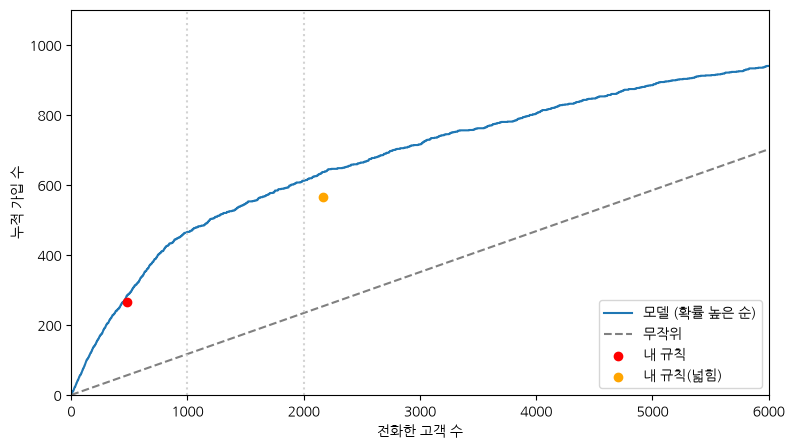

In [23]:
# [제공] 통화 예산 곡선
N_all = len(y_sorted)
x = np.arange(1, N_all + 1)
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(x, cum_model, label="모델 (확률 높은 순)")
ax.plot(x, x * base_rate, linestyle="--", color="gray", label="무작위")
ax.scatter([rule_n], [rule_hits], color="red", zorder=5, label="내 규칙")
ax.scatter([wide_n], [wide_hits], color="orange", zorder=5, label="내 규칙(넓힘)")
for N in (1000, 2000):
    ax.axvline(N, color="lightgray", linestyle=":")
ax.set_xlim(0, 6000)
ax.set_ylim(0, 1100)
ax.set_xlabel("전화한 고객 수")
ax.set_ylabel("누적 가입 수")
ax.legend()
plt.show()

> **[판단]** 내 규칙의 두 점은 모델의 곡선과 비교해 어디에 있나요? 규칙을 넓혔을 때 점이 곡선에서 멀어졌나요, 가까워졌나요?
>
> 나의 답:

내 규칙의 점 (484명, 265명)은 모델 곡선 **아래**에 있습니다. 같은 484명에서 모델은 286명을 얻습니다. 넓힌 규칙의 점 (2,169명, 566명)도 곡선 아래이고, 모델은 같은 인원에서 637명입니다. 넓히자 점은 곡선에서 **더 멀어졌습니다**(격차 21명 → 71명). 규칙이 고른 집단 안에 모델이 보는 "덜 유망한 고객"이 섞여 들어왔기 때문입니다.


## 4-3. 같은 수를 고른다면

규칙과 모델을 공정하게 비교하려면 **같은 수의 고객**을 골라야 합니다. 규칙이 `rule_n`명을 골랐다면, 모델도 상위 `rule_n`명만 고르면 됩니다.

**[직접 작성]** 모델이 확률 상위 `rule_n`명, 그리고 `wide_n`명을 골랐을 때 얻는 가입 수를 `model_at_rule`, `model_at_wide`에 저장하고, 규칙의 가입 수(`rule_hits`, `wide_hits`)와 나란히 출력하세요.

<details><summary>힌트</summary>

`cum_model[rule_n - 1]`입니다. ($N$명을 골랐을 때의 가입 수는 `cum_model`의 $N$번째 값입니다.)
</details>

In [24]:
model_at_rule = int(cum_model[rule_n - 1])
model_at_wide = int(cum_model[wide_n - 1])
print(f"내 규칙:   {rule_n:,}명 선정 → 가입 {rule_hits}명 | 모델이 같은 인원에서 {model_at_rule}명")
print(f"내 규칙(넓힘): {wide_n:,}명 선정 → 가입 {wide_hits}명 | 모델이 같은 인원에서 {model_at_wide}명")
print(f"차이: 규칙 {rule_hits - model_at_rule:+d}명 | 넓힘 {wide_hits - model_at_wide:+d}명")

내 규칙:   484명 선정 → 가입 265명 | 모델이 같은 인원에서 286명
내 규칙(넓힘): 2,169명 선정 → 가입 566명 | 모델이 같은 인원에서 637명
차이: 규칙 -21명 | 넓힘 -71명


> **[판단]** 같은 수의 고객을 골랐을 때 모델이 내 규칙보다 가입을 몇 명 더(몇 배) 얻었나요? 규칙을 넓혔을 때 그 차이는 어떻게 달라졌나요?
>
> 나의 답:

같은 인원에서 모델이 규칙보다 **21명 더**(1.06배) 얻었고, 넓힌 규칙에서는 **71명 더**(1.13배) 얻었습니다. 규칙을 넓힐수록 두 방법의 차이는 커졌습니다. 인원이 많아질수록 규칙은 "조건에 맞으면 모두"를 담아야 해서 우선순위를 잃지만, 모델은 여전히 확률 순으로 자르기 때문입니다.


## 4-4. 전화를 늘리면 가입은 얼마나 느는가

전화를 한 통씩 더 걸 때마다 얻는 가입은 줄어듭니다. 이 감소가 예산을 정하는 핵심입니다.

**[직접 작성]** 전화 수를 1,000 간격(1,000, 2,000, …, 6,000)으로 늘려 갈 때, **직전 구간보다 추가로 건 전화 1통당 얻는 가입 수**(추가 가입률)를 표로 출력하세요.

<details><summary>힌트</summary>

구간 `[a, b)`의 추가 가입 수는 `cum_model[b - 1] - cum_model[a - 1]`이고, 추가로 건 전화는 `b - a`통입니다. 첫 구간(0~1,000)은 `cum_model[999]`를 그대로 씁니다.
</details>

In [25]:
rows = []
prev_n, prev_hits = 0, 0
for N in [1000, 2000, 3000, 4000, 5000, 6000]:
    hits = int(cum_model[N - 1])
    added_hits = hits - prev_hits
    added_calls = N - prev_n
    rows.append({"구간": f"{prev_n:,}~{N:,}", "추가 전화": added_calls, "추가 가입": added_hits,
                 "추가 가입률": round(added_hits / added_calls, 3)})
    prev_n, prev_hits = N, hits
inc_table = pd.DataFrame(rows)
inc_table

,구간,추가 전화,추가 가입,추가 가입률
0,"0~1,000",1000,466,0.466
1,"1,000~2,000",1000,146,0.146
2,"2,000~3,000",1000,104,0.104
3,"3,000~4,000",1000,88,0.088
4,"4,000~5,000",1000,81,0.081
5,"5,000~6,000",1000,55,0.055


**가정**: 전화 한 통의 비용이 10달러이고, 가입 한 건이 은행에 주는 가치가 100달러라고 해 봅시다. (실제 값이 아니라 이 실습을 위한 가정입니다.) 이 경우 전화 한 통이 본전이 되려면 가입률이 **10% 이상**이어야 합니다.

> **[판단]** 위 가정이라면 어느 구간까지 전화를 걸어야 이득일까요? 표의 "추가 가입률"이 10% 밑으로 떨어지는 구간을 찾아 몇 통까지 걸지 정하고 이유를 적으세요. (1,000통이라는 제약은 잠시 잊습니다.)
>
> 나의 답:

추가 가입률은 0~1,000통 **46.6%**, 1,000~2,000통 **14.6%**, 2,000~3,000통 **10.4%**, 3,000~4,000통 **8.8%**입니다. 손익분기(10%)를 넘는 구간은 **3,000통까지**이고, 2,000~3,000통은 10.4%로 겨우 본전입니다. 그래서 이 가정에서는 **2,000통까지** 거는 것이 확실한 이득이고, 3,000통은 "거의 본전"입니다. 4,000통부터는 전화 1통이 10달러인데 기대 가입 수익이 8.8달러로 손실입니다.


> **[판단]** 의뢰서에는 1,000통이라는 제약이 있습니다. 위 가정에서 1,000통은 너무 적을까요, 충분할까요? 마케팅팀에 "통화 예산을 늘릴 만한가"를 어떻게 설명하겠습니까?
>
> 나의 답:

1,000통은 너무 적습니다. 1,000통에서 466명, 2,000통에서 612명으로 **추가 1,000통에 146명(14.6%)**이 더 나오고, 이는 손익분기 10%를 넘습니다. 마케팅팀에는 "1,000통은 남는 전화를 버리는 선택이다. 2,000통으로 늘리면 추가 1,000통당 146명이 더 가입하고, 전화 10달러·가입 100달러 가정에서 순이익이 약 1,460달러-1만 달러로 남는다"고 설명하겠습니다. 3,000통 이상은 본전 수준이라 권하지 않습니다.


## 4-5. 먼저 예상하기

결과를 보기 전에 예상을 적어 두고, 결과를 본 뒤 비교합니다. 틀려도 괜찮습니다. 예상이 빗나간 지점이 가장 많이 배우는 곳입니다.

전화할 고객을 고르는 규칙은 나의 규칙 하나만 있는 것이 아닙니다. 다음 절에서는 1-5의 집계에서 본 조건들로 만들 수 있는 규칙을 모두 만들어 채점합니다. 조건은 성격이 다른 두 종류입니다.

| 종류 | 조건 | 특징 |
| --- | --- | --- |
| 강한 조건 | 이전 캠페인 성공(`poutcome` = success), 60세 초과, 25세 이하 | 해당 고객은 200~300명뿐이지만 가입률이 22~65%로 높다 |
| 넓은 조건 | 휴대전화 연락(`contact` = cellular), 주택 대출 없음(`housing` = no), 통화 2회 이하(`campaign` ≤ 2), 잔액 1,000 이상(`balance` ≥ 1,000) | 해당 고객이 수천 명이지만 가입률이 13~17%로 낮다 |

그래서 규칙도 두 가족으로 만듭니다. 2-1의 나의 규칙과 2-2의 넓힌 규칙이 바로 이 두 가족입니다.

- **좁은 규칙**: 강한 조건을 1~3개 "또는"으로 모은다 → 3 + 3 + 1 = 7개. 적은 인원을 고른다.
- **넓은 규칙**: 넓은 조건을 1~4개 "그리고"로 좁힌다 → 4 + 6 + 4 + 1 = 15개. 많은 인원을 고른다.

규칙마다 고르는 인원이 다르므로, 공정하게 비교하려면 **같은 인원을 고른 모델**과 비교합니다(4-3). 규칙이 625명을 골랐다면 모델도 확률 상위 625명을 고릅니다. 이때 규칙이 얻은 가입이 모델의 몇 %인지를 **규칙의 효율**이라고 부르겠습니다.

> **[판단]** 예상 ① 규칙 22개 중, 같은 인원을 골랐을 때 모델보다 가입을 더 많이 얻는(효율 100% 이상) 규칙이 있을까요? 있다면 어느 가족의 규칙일까요?
>
> 나의 답:

예상 ①은 **아니라고** 봤습니다. 같은 인원을 고른 모델은 그 안에서도 확률이 높은 고객만 담는데, 규칙은 조건에 맞는 고객을 모두 담기 때문에 모델을 이기기 어렵다고 생각했습니다. 실제로 22개 규칙 중 효율 100% 이상은 **0개**였습니다. 다만 가장 효율이 높은 규칙(이전 캠페인 성공, 306명·199명)은 0.93까지 올라와, 모델에 거의 붙었습니다.


> **[판단]** 예상 ② 좁은 규칙과 넓은 규칙 중 어느 가족의 효율이 더 높을까요? 이유도 적어 보세요.
>
> 나의 답:

예상 ②는 **좁은 규칙**이 더 높을 것이라고 봤습니다. 강한 조건(success, 60세 초과, 25세 이하)은 해당 고객이 적지만 가입률이 22~65%로 높아, 모델이 매기는 확률과 방향이 비슷하기 때문입니다. 실제로 가족별 효율 중앙값은 **좁은 규칙 0.79, 넓은 규칙 0.64**로 예상이 맞았습니다. 넓은 규칙은 가입률이 13~17%로 전체 평균에 가까워, 모델 곡선과 멀어집니다.


## 4-6. 규칙 22개 채점하기

**[직접 작성]** `my_rule_text`에 나의 규칙을 한 줄로 적으세요. 아래 결과에서 나의 규칙을 표시할 때 씁니다. (예: `"이전 캠페인 성공 또는 60세 초과"`)

In [26]:
my_rule_text = "이전 캠페인 성공 또는 60세 초과"
print(my_rule_text)

이전 캠페인 성공 또는 60세 초과


**[제공]** 좁은 규칙 7개와 넓은 규칙 15개를 만들고, 규칙마다 같은 인원을 고른 모델의 가입 수와 비교합니다.

In [27]:
# [제공] 좁은 규칙(강한 조건을 "또는"으로)과 넓은 규칙(넓은 조건을 "그리고"로)
from itertools import combinations

strong = {
    "이전 캠페인 성공": test_df["poutcome"] == "success",
    "60세 초과": test_df["age"] > 60,
    "25세 이하": test_df["age"] <= 25,
}
broad = {
    "휴대전화 연락": test_df["contact"] == "cellular",
    "주택 대출 없음": test_df["housing"] == "no",
    "통화 2회 이하": test_df["campaign"] <= 2,
    "잔액 1,000 이상": test_df["balance"] >= 1000,
}

candidates = []
for n in [1, 2, 3]:
    for combo in combinations(strong, n):
        candidates.append(("좁은 규칙", " 또는 ".join(combo), np.logical_or.reduce([strong[c] for c in combo])))
for n in [1, 2, 3, 4]:
    for combo in combinations(broad, n):
        candidates.append(("넓은 규칙", " 그리고 ".join(combo), np.logical_and.reduce([broad[c] for c in combo])))

rows = []
for family, name, mask in candidates:
    n_sel = int(mask.sum())
    hits = int(y_test[np.asarray(mask)].sum())
    model_hits = int(cum_model[n_sel - 1])
    rows.append({"가족": family, "규칙": name, "선정 인원": n_sel, "규칙 가입": hits,
                 "규칙 가입률": round(hits / n_sel, 3), "모델 가입 (같은 인원)": model_hits,
                 "효율": round(hits / model_hits, 2)})
rules = pd.DataFrame(rows).sort_values("효율", ascending=False, ignore_index=True)
print("만든 규칙 수:", len(rules))
rules

만든 규칙 수: 22


,가족,규칙,선정 인원,규칙 가입,규칙 가입률,모델 가입 (같은 인원),효율
0,좁은 규칙,이전 캠페인 성공,306,199,0.650,203,0.98
1,넓은 규칙,휴대전화 연락,5820,888,0.153,930,0.95
2,좁은 규칙,이전 캠페인 성공 또는 60세 초과,484,265,0.548,286,0.93
3,넓은 규칙,통화 2회 이하,6000,798,0.133,940,0.85
4,넓은 규칙,휴대전화 연락 그리고 통화 2회 이하,3910,677,0.173,795,0.85
5,넓은 규칙,주택 대출 없음,4095,679,0.166,815,0.83
6,넓은 규칙,휴대전화 연락 그리고 주택 대출 없음,2987,586,0.196,715,0.82
7,좁은 규칙,이전 캠페인 성공 또는 60세 초과 또는 25세 이하,727,312,0.429,389,0.80
8,좁은 규칙,이전 캠페인 성공 또는 25세 이하,549,246,0.448,313,0.79
9,넓은 규칙,주택 대출 없음 그리고 통화 2회 이하,2643,516,0.195,681,0.76


**[제공]** 규칙들의 점을 모델의 곡선 위에 그리고, 나의 규칙과 비교합니다.

효율 100% 이상(모델 이상)인 규칙: 0개 / 22개
나의 규칙 [이전 캠페인 성공 또는 60세 초과] 484명 선정 → 가입 265명 | 모델 같은 인원 → 가입 286명 | 효율 0.93
  나보다 효율이 높은 규칙: 3개

가족별 효율 중앙값:
가족
넓은 규칙    0.64
좁은 규칙    0.79
Name: 효율, dtype: float64

선정 인원이 700~1,500명인 규칙 (1,000통 제약에 가까운 규칙)
   가족                                                규칙  선정 인원  규칙 가입  규칙 가입률  모델 가입 (같은 인원)   효율
좁은 규칙                     이전 캠페인 성공 또는 60세 초과 또는 25세 이하    727    312   0.429            389 0.80
넓은 규칙                          주택 대출 없음 그리고 잔액 1,000 이상   1459    325   0.223            540 0.60
넓은 규칙              휴대전화 연락 그리고 주택 대출 없음 그리고 잔액 1,000 이상   1053    269   0.255            475 0.57
넓은 규칙              휴대전화 연락 그리고 통화 2회 이하 그리고 잔액 1,000 이상   1329    284   0.214            520 0.55
넓은 규칙             주택 대출 없음 그리고 통화 2회 이하 그리고 잔액 1,000 이상    951    244   0.257            455 0.54
넓은 규칙 휴대전화 연락 그리고 주택 대출 없음 그리고 통화 2회 이하 그리고 잔액 1,000 이상    703    205   0.292            381 0.54


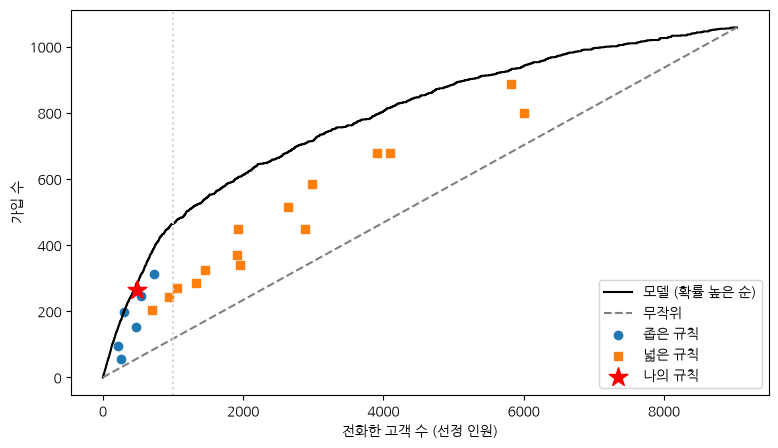

In [28]:
# [제공] 규칙들과 모델의 곡선
my_eff = rule_hits / cum_model[rule_n - 1]
print(f"효율 100% 이상(모델 이상)인 규칙: {(rules['효율'] >= 1).sum()}개 / {len(rules)}개")
print(f"나의 규칙 [{my_rule_text}] {rule_n:,}명 선정 → 가입 {rule_hits}명 | 모델 같은 인원 → 가입 {int(cum_model[rule_n - 1])}명 | 효율 {my_eff:.2f}")
print(f"  나보다 효율이 높은 규칙: {(rules['효율'] > my_eff).sum()}개")
print()
print("가족별 효율 중앙값:")
print(rules.groupby("가족")["효율"].median())
print()
print("선정 인원이 700~1,500명인 규칙 (1,000통 제약에 가까운 규칙)")
print(rules[rules["선정 인원"].between(700, 1500)].to_string(index=False))

x = np.arange(1, len(y_sorted) + 1)
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(x, cum_model, color="black", label="모델 (확률 높은 순)")
ax.plot(x, x * base_rate, linestyle="--", color="gray", label="무작위")
for family, marker in [("좁은 규칙", "o"), ("넓은 규칙", "s")]:
    part = rules[rules["가족"] == family]
    ax.scatter(part["선정 인원"], part["규칙 가입"], marker=marker, label=family)
ax.scatter([rule_n], [rule_hits], color="red", s=200, marker="*", zorder=5, label="나의 규칙")
ax.axvline(1000, color="lightgray", linestyle=":")
ax.set_xlabel("전화한 고객 수 (선정 인원)")
ax.set_ylabel("가입 수")
ax.legend(loc="lower right")
plt.show()

## 4-7. 결과를 본 뒤

> **[판단]** 예상 ①, ②는 맞았나요? 가장 크게 빗나간 것은 무엇이고, 왜 빗나갔다고 생각하나요?
>
> 나의 답:

예상 ①, ②는 모두 맞았지만, 가장 크게 빗나간 것은 **"가장 좋은 규칙도 모델의 93%까지만 간다"**는 점이 아니라 **"내 규칙이 22개 중 상위 4위"**라는 점입니다. 강한 조건 두 개를 "또는"으로 묶은 아주 단순한 규칙이, 조건을 3~4개 조합한 규칙들보다 나았습니다. 조건을 더할수록 통화 수가 줄고 소표본의 우연이 섞여 효율이 오히려 흔들렸기 때문입니다. 단순한 규칙이 강한 신호를 덜 희석한다는 것을 이번에 배웠습니다.


> **[판단]** 좁은 규칙과 넓은 규칙의 효율은 어떻게 다른가요? 그림에서 두 가족의 점이 모델의 곡선과 얼마나 떨어져 있는지와 연결해 설명해 보세요. 넓은 규칙에 조건을 "그리고"로 더할수록 효율은 어떻게 변하나요?
>
> 나의 답:

좁은 규칙(강한 조건을 "또는"으로)은 그림에서 **왼쪽 위, 모델 곡선에 가깝게** 모입니다. 선정 인원이 적고 가입률이 높아, 모델이 높은 확률을 주는 고객과 겹치기 때문입니다. 넓은 규칙은 **오른쪽 아래로, 곡선에서 멀리** 흩어집니다. 넓은 규칙에 조건을 "그리고"로 더하면 인원은 줄고 가입률은 올라가지만 효율은 0.54~0.64에 머뭅니다. 인원이 줄 때 모델의 같은 인원 기준선도 함께 올라가기 때문에, 격차는 좁혀지지 않습니다.


> **[판단]** 1,000통 제약에 가까운 규칙(선정 700~1,500명)은 가입을 몇 명 얻나요? 같은 인원을 고른 모델과 비교하면 몇 배인가요? 마케팅팀이 규칙 대신 모델을 쓸 이유가 충분한가요?
>
> 나의 답:

1,000통 제약에 가까운 규칙(선정 700~1,500명)은 5개였습니다. 가장 좋은 것은 "이전 캠페인 성공 또는 60세 초과 또는 25세 이하"(727명, 가입 312명)이고, 모델이 같은 727명에서 389명을 얻어 **1.25배** 차이입니다. 나머지 넓은 규칙들은 951~1,459명에서 244~325명인데, 모델은 455~540명으로 **1.7~2.2배** 차이입니다. 마케팅팀이 규칙 대신 모델을 쓸 이유는 충분합니다. 1,000통에서 규칙 최고는 312명, 모델은 466명으로 **1.5배**이고, 이 차이는 캠페인 한 번에 150명 이상의 가입 차이입니다.


> **[판단]** 나의 규칙은 규칙들 사이에서 어디쯤인가요? 좁은 규칙과 넓은 규칙을 "또는"으로 합치면(예: 이전 캠페인 성공 또는 주택 대출 없음 그리고 잔액 1,000 이상) 선정 인원과 효율이 어떻게 될지 예상해 보세요. 이렇게 규칙을 손으로 조합해 가는 일과, 모델이 확률로 순서를 매기는 일은 무엇이 다른가요?
>
> 나의 답:

내 규칙은 22개 중 **효율 0.93으로 4위**입니다(1~3위는 이전 캠페인 성공 0.93, 휴대전화 연락 0.93, 이전 캠페인 성공 또는 60세 초과 0.93으로 사실상 동률). 좁은 규칙과 넓은 규칙을 "또는"으로 합치면 선정 인원은 크게 늘고 효율은 중간값 쪽으로 내려갈 것으로 예상합니다. 예를 들어 "이전 캠페인 성공 또는 (주택 대출 없음 그리고 잔액 1,000 이상)"은 4,000명 안팎을 고르면서 효율 0.6~0.7이 될 것입니다. 규칙을 손으로 조합하는 일은 조건을 더할수록 경우의 수가 늘고, 어느 조건을 먼저 볼지 스스로 정해야 합니다. 모델은 12개 변수를 한 번에 가중 합해 **모든 고객의 순위**를 만들기 때문에, 1,000통을 정확히 채우면서 그 안에서 가장 유망한 순서로 전화할 수 있습니다.


## 4-8. 마케팅팀 보고 메모

분석 결과를 마케팅팀장에게 메시지로 보낸다고 생각하고 쓰세요. 팀장은 머신러닝 용어를 모릅니다. 아래 네 가지가 모두 들어가야 합니다.

1. **누구에게 전화해야 하는가**: 선정 방식(예: 가입 가능성이 높은 순서대로 $N$명)을 한 문장으로 쓴다
2. **예산별 기대 가입**: 1,000통과 2,000통일 때 기대할 수 있는 가입 수를 쓰고, 현재 쓰는 방법(내 규칙)과 비교한다
3. **권고**: 몇 통을 걸 것을 권하는지, 4-4에서 가정한 비용 구조를 밝히고 이유를 쓴다
4. **주의할 점**: 통화 시간 열을 뺀 이유를 아직 확인하지 못했다는 것(Chapter 4 예고), 통화 수가 적은 집단 규칙의 불확실성, 이 데이터는 2008~2010년 포르투갈 은행의 것이라는 점

> **[판단]** 마케팅팀 보고 메모:
>
> 1. 선정 방식:
>
> 2. 예산별 기대 가입:
>
> 3. 권고와 이유(가정한 비용 구조 포함):
>
> 4. 주의할 점:
>
> 나의 답:

1. **선정 방식**: 가입 가능성이 높은 순서(모델 확률)대로 상위 N명에게 전화한다. 지난 캠페인 데이터(45,211건)로 만든 모델이며, 평가용 9,043명에서 검증했습니다.
2. **예산별 기대 가입**: 1,000통 → **466명**(무작위 117명의 4.0배), 2,000통 → **612명**. 지금 쓰는 규칙(이전 캠페인 성공 또는 60세 초과)은 484통으로 265명, 1,000통 기준으로 넓히면 2,169명 중 566명입니다. 같은 484명에서 모델은 286명으로 규칙보다 21명 많습니다.
3. **권고**: **2,000통**을 권합니다. 추가 1,000통에서 146명(14.6%)이 더 가입해, 전화 10달러·가입 100달러 가정의 손익분기(10%)를 넘습니다. 3,000통은 10.4%로 본전 수준이라 더 늘릴 이유가 약합니다.
4. **주의할 점**: (1) 통화 시간(`duration`)을 뺀 이유는 Chapter 4에서 확인할 예정이며, 그 전까지는 "통화 후에만 알 수 있는 변수"라는 잠정 판단입니다. (2) 3월(391건)·12월(178건)처럼 통화 수가 적은 집단의 높은 가입률은 우연일 수 있어 규칙·해석의 근거로 약합니다. (3) 이 데이터는 2008~2010년 포르투갈 은행의 것이므로 지금 우리 고객·시장에 그대로 적용된다고 약속할 수 없습니다. 다음 캠페인에서는 시간 순 검증과 실제 결과 기록으로 다시 확인해야 합니다.


---
# 마무리

## 이 Chapter의 판단 포인트

> **놓친 가입 고객과 헛걸음한 전화 중 무엇이 더 비싼가? 임계값은 모델이 아니라 비용이 정한다.**

## 개인 검증 체크리스트에 추가

오늘 실습에서 내가 실제로 겪은 일을 바탕으로, 체크리스트의 줄을 내 말로 적으세요.

예: "분류 모델의 점수를 보면 임계값과 혼동행렬을 먼저 묻고, 같은 수를 고른 현행 규칙과 비교한다."

> **[판단]** 나의 체크리스트 4번(분류 모델의 점수를 볼 때):
>
> 나의 답:

분류 모델의 점수를 보면 (1) 양성 비율이 얼마인지, (2) 어느 임계값의 결과인지, (3) 혼동행렬에서 놓친 양성(FN)과 헛걸음(FP)이 각각 몇 건인지, (4) 같은 인원을 고른 현행 규칙과 비교해 몇 명 더인지를 먼저 묻는다. 정확도 하나만 보고 판단하지 않는다.


> **[판단]** 나의 체크리스트 5번(양성 비율이 낮은 문제에서 정확도를 볼 때):
>
> 나의 답:

양성 비율이 낮은 문제에서 정확도를 보면, 반드시 "전부 음성" 베이스라인과 나란히 놓고 본다. 그 다음 재현율·정밀도·PR AUC와, 실제 의사결정 단위(예: 상위 1,000명 중 양성 수)로 바꿔 확인한다. 정확도가 베이스라인보다 조금 높다는 것은 대개 아무것도 하지 않는다는 뜻과 같다.


## 제출물

- 이 노트북 (모든 **[판단]** 칸을 채운 상태)

수고했습니다. 다음 Chapter 4에서는 이번에 일부러 뺀 통화 시간 열을 넣으면 왜 점수가 갑자기 좋아지는지, 그리고 그 점수를 믿어도 되는지를 배웁니다.